In [2]:
import re

import matplotlib.pyplot as plt
import numpy as np


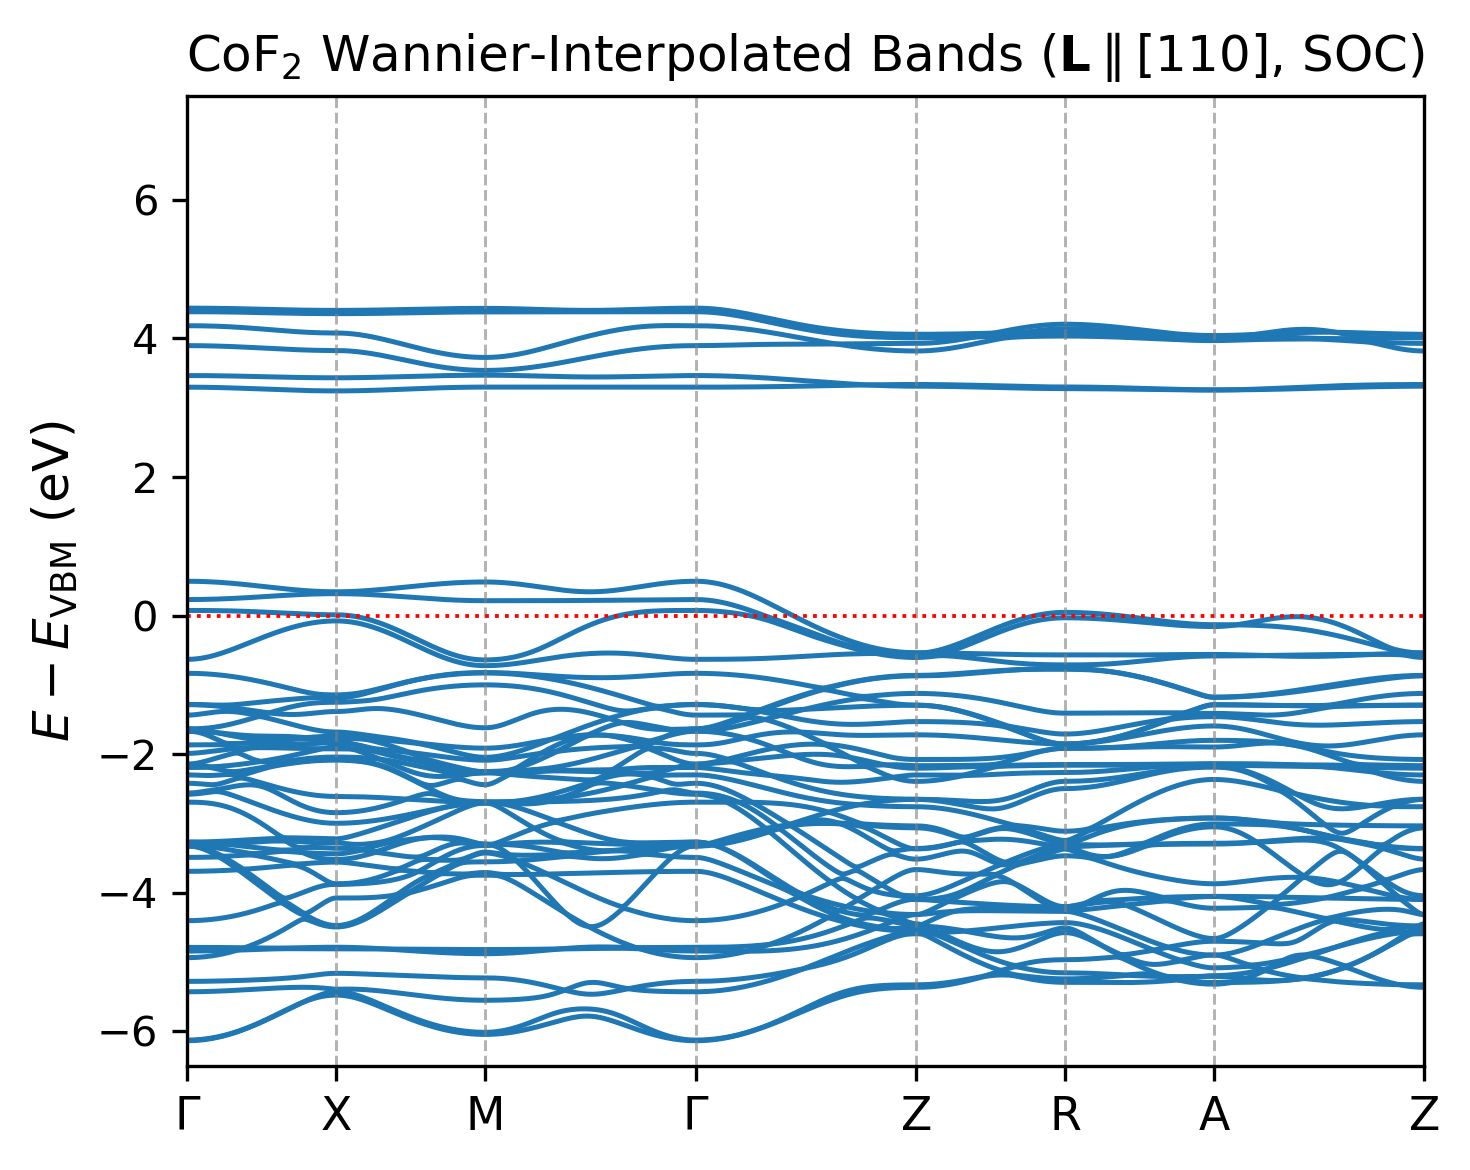

In [6]:
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans"]

with open("cof2_band.dat") as f:
  blocks = re.split(r"\n\s*\n", f.read().strip())

ticks, labels = [], []
with open("cof2_band.gnu") as f:
  for line in f:
    if "set xtics" in line:
      items = line.split("(")[1].split(")")[0].split(",")
      for item in items:
        raw_lbl, pos = item.strip().rsplit(" ", 1)
        lbl = raw_lbl.strip().strip('"').strip()
        labels.append(r"$\Gamma$" if lbl == "G" else lbl)
        ticks.append(float(pos))

vbm = 4.9578  # Top of valence band at Gamma from soc.out

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
for blk in blocks:
  if not blk.strip():
    continue
  data = np.loadtxt(blk.splitlines())
  ax.plot(data[:, 0], data[:, 1] - vbm, color="#1f77b4", lw=1.2)

for t in ticks:
  ax.axvline(t, color="gray", ls="--", lw=0.7, alpha=0.6)
ax.axhline(0, color="red", ls=":", lw=0.9, label="VBM")

ax.set_xticks(ticks)
ax.set_xticklabels(labels, fontsize=11)
ax.set_xlim(ticks[0], ticks[-1])
ax.set_ylim(-6.5, 7.5)
ax.set_ylabel(r"$E - E_{\mathrm{VBM}}$ (eV)", fontsize=12)
ax.set_title(
    r"CoF$_2$ Wannier-Interpolated Bands ($\mathbf{L} \parallel [110]$, SOC)",
    fontsize=12,
)
plt.tight_layout()
# plt.savefig("cof2_wan_bands_clean.png", dpi=300) 
plt.show()

In [4]:
import numpy as np

data = np.loadtxt('eig_sorted.dat')  # columns: kpt, band, energy
nk = int(data[:,0].max())
nbnd = int(data[:,1].max())
print(f"nk={nk}, nbnd={nbnd}")  # should print nk=288, nbnd=56

# reshape: data is already ordered kpt-major (slow), band-minor (fast)
E = data[:,2].reshape(nk, nbnd)

for n in range(1, nbnd):
    max_below = E[:, n-1].max()
    min_above = E[:, n].min()
    gap = min_above - max_below
    if gap > 0:
        orig_band_below = n + 24
        orig_band_above = n + 1 + 24
        print(f"Gap between orig band {orig_band_below} and {orig_band_above}: "
              f"{max_below:.3f} -> {min_above:.3f} eV (gap={gap:.3f})")

nk=288, nbnd=56
Gap between orig band 58 and 59: 4.215 -> 4.235 eV (gap=0.019)
Gap between orig band 62 and 63: 5.453 -> 8.201 eV (gap=2.748)
Gap between orig band 64 and 65: 8.427 -> 8.497 eV (gap=0.069)
Gap between orig band 68 and 69: 9.395 -> 9.436 eV (gap=0.041)
